┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie C:\Users\vishw\.julia\packages\Makie\Iy6pu\src\scenes.jl:264


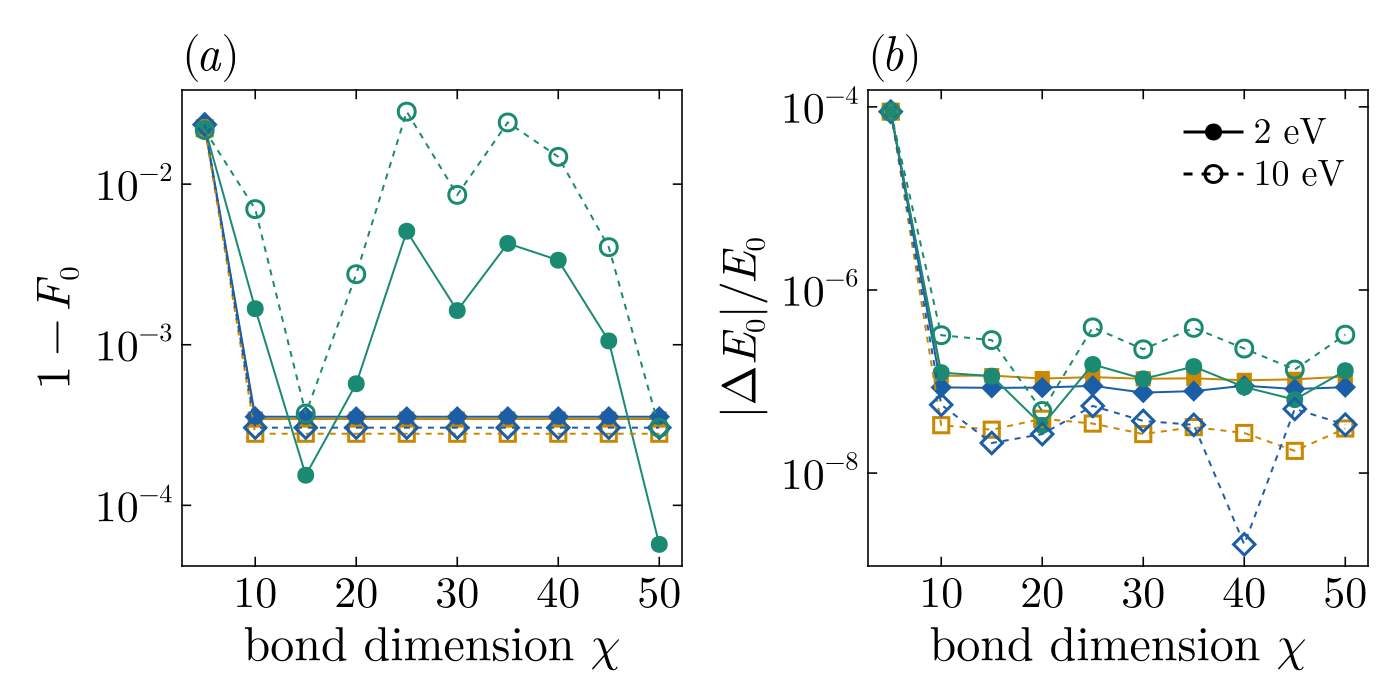

┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie C:\Users\vishw\.julia\packages\Makie\Iy6pu\src\scenes.jl:264


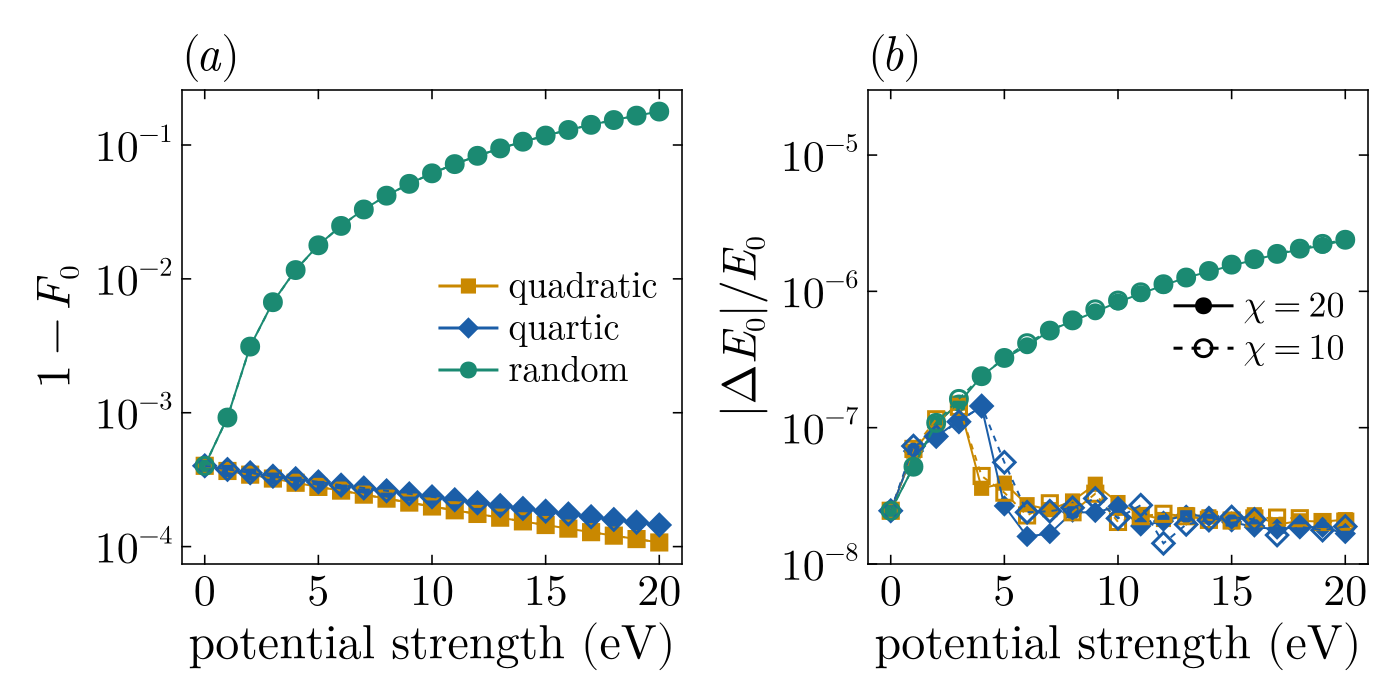

In [1]:
using CairoMakie, DataFrames, XLSX

pots = [:quad => "quadratic", :quartic => "quartic", :random => "random"]

function load_run(sheet)
    df = DataFrame(XLSX.readtable("simulation_data.xlsx", sheet))
    x  = Float64.(df[!, 1])
    F  = Dict(p => Float64.(df[!, "1-F0_$n"]) for (p, n) in pots)
    E  = Dict(p => Float64.(df[!, "relE_$n"]) for (p, n) in pots)
    (x = x, F = F, E = E)
end

bd_2eV   = load_run("BD_2eV")
bd_10eV  = load_run("BD_10eV")
st_chi20 = load_run("ST_chi20")
st_chi10 = load_run("ST_chi10")

set_theme!(Theme(
    fontsize = 11,
    font = "Times New Roman",
    backgroundcolor = :white,
    Axis = (
        xgridvisible = false, ygridvisible = false,
        spinewidth = 0.8, xtickwidth = 0.8, ytickwidth = 0.8,
        xticksize = 5, yticksize = 5,
        titlesize = 24, titlealign = :left,
        xlabelsize = 24, ylabelsize = 24,
        xticklabelsize = 22, yticklabelsize = 22,
        xtickalign = 1, ytickalign = 1,
        xminortickalign = 1, yminortickalign = 1,
        xticksmirrored = true, yticksmirrored = true,
    ),
    Lines  = (linewidth = 1,),
    Legend = (framevisible = false, labelsize = 18, patchsize = (30, 15),
              backgroundcolor = :transparent),
))

colors  = (quad = RGBf(0.788, 0.533, 0.0),
           quartic = RGBf(0.106, 0.369, 0.659),
           random = RGBf(0.106, 0.541, 0.447))
markers = (quad = :rect, quartic = :diamond, random = :circle)

function plot_run!(ax, run, key; linestyle = :solid, hollow = false)
    for (p, _) in pots
        y = getproperty(run, key)[p]
        lines!(ax, run.x, y; color = colors[p], linestyle = linestyle)
        scatter!(ax, run.x, y;
            color       = hollow ? :transparent : colors[p],
            strokecolor = colors[p],
            strokewidth = hollow ? 1.5 : 0,
            markersize  = 12,
            marker      = markers[p])
    end
end

color_entries = [[LineElement(color = colors[p]),
                  MarkerElement(marker = markers[p], color = colors[p], markersize = 12)] for (p, _) in pots]
color_labels  = [L"quadratic$$", L"quartic$$", L"random$$"]

solid_entry = [LineElement(color = :black, linestyle = :solid),
               MarkerElement(marker = :circle, color = :black, markersize = 12)]
dash_entry  = [LineElement(color = :black, linestyle = :dash),
               MarkerElement(marker = :circle, color = :transparent, strokecolor = :black,
                             strokewidth = 1.5, markersize = 12)]

fid_yticks   = ([1e-4, 1e-3, 1e-2, 1e-1], [L"$10^{-4}$", L"$10^{-3}$", L"$10^{-2}$", L"$10^{-1}$"])
en_yticks_bd = ([1e-8, 1e-6, 1e-4],       [L"$10^{-8}$", L"$10^{-6}$", L"$10^{-4}$"])
en_yticks_st = ([1e-8, 1e-7, 1e-6, 1e-5], [L"$10^{-8}$", L"$10^{-7}$", L"$10^{-6}$", L"$10^{-5}$"])
bd_xticks    = ([10, 20, 30, 40, 50],     [L"$10$", L"$20$", L"$30$", L"$40$", L"$50$"])
st_xticks    = ([0, 5, 10, 15, 20],       [L"$0$", L"$5$", L"$10$", L"$15$", L"$20$"])


fig_bd = Figure(resolution = (700, 350))

ax_bd1 = Axis(fig_bd[1, 1], xlabel = L"bond dimension $\chi$", ylabel = L"$1-F_0$",
              yscale = log10, title = L"$(a)$", xticks = bd_xticks, yticks = fid_yticks)
ax_bd2 = Axis(fig_bd[1, 2], xlabel = L"bond dimension $\chi$", ylabel = L"$|\Delta E_0|/E_0$",
              yscale = log10, title = L"$(b)$", xticks = bd_xticks, yticks = en_yticks_bd)

plot_run!(ax_bd1, bd_2eV,  :F)
plot_run!(ax_bd1, bd_10eV, :F; linestyle = :dash, hollow = true)
plot_run!(ax_bd2, bd_2eV,  :E)
plot_run!(ax_bd2, bd_10eV, :E; linestyle = :dash, hollow = true)

axislegend(ax_bd2, [solid_entry, dash_entry], [L"$2$ eV", L"$10$ eV"]; position = :rt)

save("BondDimension_TwoPanel_PRL_2.pdf", fig_bd)
display(fig_bd)


fig_st = Figure(resolution = (700, 350))

ax_st1 = Axis(fig_st[1, 1], xlabel = L"potential strength (eV)$$", ylabel = L"$1-F_0$",
              yscale = log10, title = L"$(a)$", xticks = st_xticks, yticks = fid_yticks)
ax_st2 = Axis(fig_st[1, 2], xlabel = L"potential strength (eV)$$", ylabel = L"$|\Delta E_0|/E_0$",
              yscale = log10, title = L"$(b)$", xticks = st_xticks, yticks = en_yticks_st)
ylims!(ax_st2, 1e-8, 3e-5)

plot_run!(ax_st1, st_chi20, :F)
plot_run!(ax_st1, st_chi10, :F; linestyle = :dash, hollow = true)
plot_run!(ax_st2, st_chi20, :E)
plot_run!(ax_st2, st_chi10, :E; linestyle = :dash, hollow = true)

axislegend(ax_st1, color_entries, color_labels; position = :rc)
axislegend(ax_st2, [solid_entry, dash_entry], [L"$\chi = 20$", L"$\chi = 10$"]; position = :rc)

save("Strength_TwoPanel_PRL_2.pdf", fig_st)
fig_st